## Why these five companies and this decade

The decade from 2000 to 2010 holds two crashes. The first is the end of the dot-com boom, which took technology shares down from early 2000 to late 2002 and 2003. The second is the financial crisis that followed the bankruptcy of Lehman Brothers on 15 September 2008. Five large technology companies priced month by month across both crashes show which firms lost the most, which recovered, and how far apart their paths ended up by March 2010.

## The dataset

`stocks.csv` is the stocks file of the vega-datasets collection, published at
<https://github.com/vega/vega-datasets/blob/main/data/stocks.csv>. The file holds 560 rows in three columns: `symbol`, `date` and `price`. Each row is the share price of one company in one month, in US dollars. Apple, Amazon, IBM and Microsoft have 123 months each, from January 2000 to March 2010. Google has 68, from August 2004, the month of its initial public offering, to March 2010. The copy in this folder was written from the version bundled with the `vega_datasets` Python package, with dates in ISO format.

## 1) Setup

In [1]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import great_tables
from great_tables import GT
sns.set_theme(style="whitegrid")
stocks = pd.read_csv("stocks.csv", parse_dates=["date"])
print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__, "| great_tables", great_tables.__version__)
print(stocks.shape)
stocks.info()

pandas 3.0.5 | matplotlib 3.11.2 | great_tables 1.0.0
(560, 3)
<class 'pandas.DataFrame'>
RangeIndex: 560 entries, 0 to 559
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   symbol  560 non-null    str           
 1   date    560 non-null    datetime64[us]
 2   price   560 non-null    float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 13.3 KB


## 2) Reshaping to one column per company

The file is long, one row per company and month. The charts need it wide, one column per company, so `pivot` turns the `symbol` column into five columns indexed by date. The tickers become company names first, so that every label in the charts and the table uses the same name.

In [2]:
names = {"AAPL": "Apple", "AMZN": "Amazon", "GOOG": "Google", "IBM": "IBM", "MSFT": "Microsoft"}
stocks["company"] = stocks["symbol"].map(names)
prices = stocks.pivot(index="date", columns="company", values="price")
print(prices.count())
prices.tail()

company
Amazon       123
Apple        123
Google        68
IBM          123
Microsoft    123
dtype: int64


company,Amazon,Apple,Google,IBM,Microsoft
date,,,,,
2009-11-01,135.91,199.91,583.00,125.79,29.27
2009-12-01,134.52,210.73,619.98,130.32,30.34
2010-01-01,125.41,192.06,529.94,121.85,28.05
2010-02-01,118.40,204.62,526.80,127.16,28.67
2010-03-01,128.82,223.02,560.19,125.55,28.80


## 3) Chart 1: Apple across the decade, with annotations

The first chart follows one company over the whole file. Apple has the widest range of the five, from $7.07 to $223.02, so it carries both crashes in a single line. Three annotations mark the March 2003 low, the release of the iPhone in June 2007 and the Lehman Brothers bankruptcy in September 2008, and each gives a date and a price.

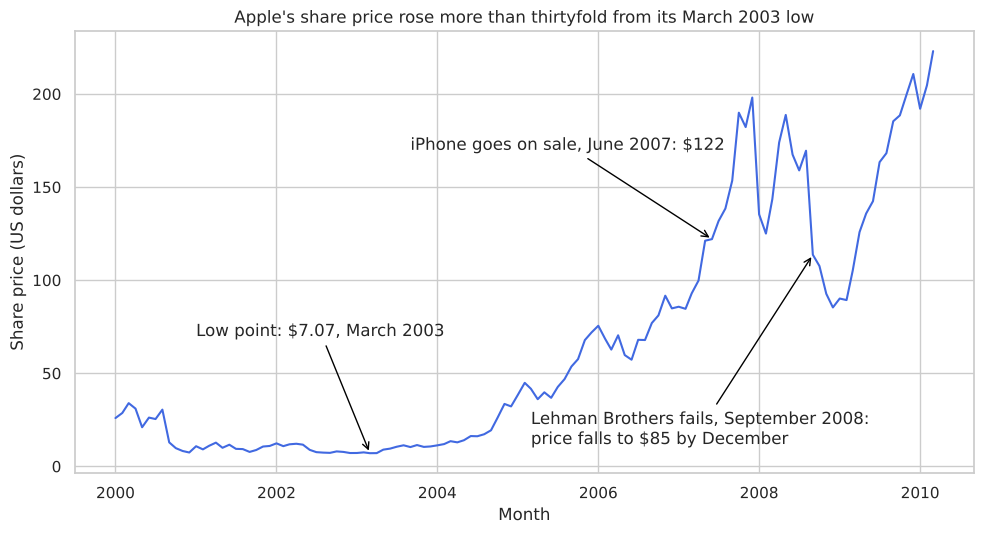

In [3]:
apple = prices["Apple"]
plt.figure(figsize=(10, 5.5))
plt.plot(apple.index, apple, color="royalblue")
plt.annotate("Low point: $7.07, March 2003", xy=(pd.Timestamp("2003-03-01"), 7.07), xytext=(pd.Timestamp("2001-01-01"), 70), arrowprops=dict(arrowstyle="->", color="black"))
plt.annotate("iPhone goes on sale, June 2007: $122", xy=(pd.Timestamp("2007-06-01"), 122.04), xytext=(pd.Timestamp("2003-09-01"), 170), arrowprops=dict(arrowstyle="->", color="black"))
plt.annotate("Lehman Brothers fails, September 2008:\nprice falls to $85 by December", xy=(pd.Timestamp("2008-09-01"), 113.66), xytext=(pd.Timestamp("2005-03-01"), 12), arrowprops=dict(arrowstyle="->", color="black"))
plt.xlabel("Month")
plt.ylabel("Share price (US dollars)")
plt.title("Apple's share price rose more than thirtyfold from its March 2003 low")
plt.tight_layout()
plt.show()

Apple lost 79 percent of its value in the first crash, from $33.95 in March 2000 to $7.07 in March 2003, and spent most of 2001 and 2002 near $10. The climb starts in 2004 and is already steep before the iPhone: the price is $122.04 in June 2007 and peaks at $198.08 in December 2007. The second crash takes it to $85.35 in December 2008, a fall of 57 percent in twelve months. By March 2010 the price is $223.02, 2.6 times the December 2008 level and above the 2007 peak.

## 4) Chart 2: five companies, labeled at the line ends

The second chart compares all five companies from August 2004, the first month with a Google price. Each series is set to 100 in that month, so a value of 300 means the price tripled. The y axis is logarithmic, so equal vertical distances are equal percentage changes. The chart has no legend: each line carries its company name and its March 2010 value at its right end, in the line's own color.

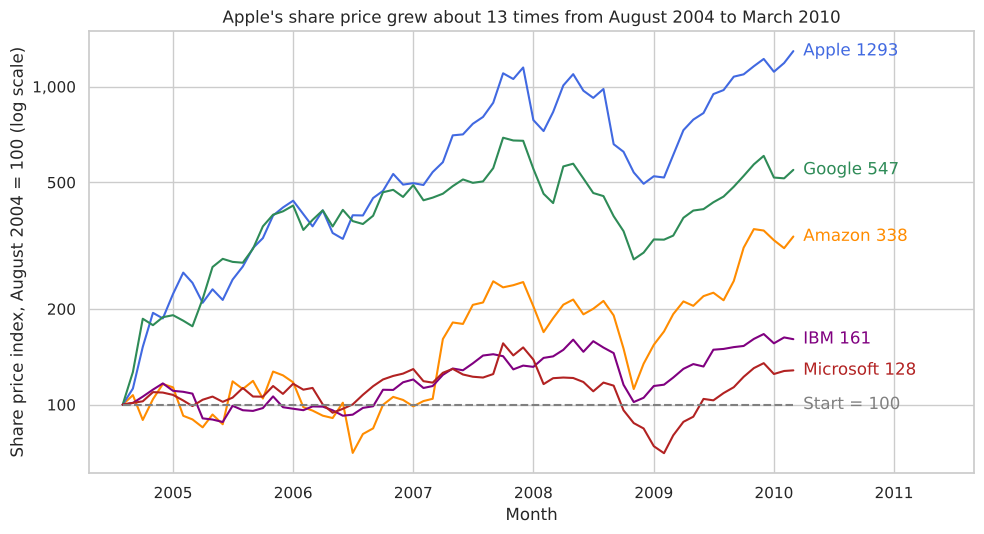

In [4]:
indexed = prices.loc["2004-08-01":] / prices.loc["2004-08-01"] * 100
colors = {"Apple": "royalblue", "Amazon": "darkorange", "Google": "seagreen", "IBM": "purple", "Microsoft": "firebrick"}
label_x = indexed.index[-1] + pd.Timedelta(days=30)
plt.figure(figsize=(10, 5.5))
for company in indexed.columns:
    plt.plot(indexed.index, indexed[company], color=colors[company])
    plt.text(label_x, indexed[company].iloc[-1], f"{company} {indexed[company].iloc[-1]:.0f}", color=colors[company], va="center")
plt.plot([indexed.index[0], indexed.index[-1]], [100, 100], color="grey", linestyle="--")
plt.text(label_x, 100, "Start = 100", color="grey", va="center")
plt.yscale("log")
plt.yticks([100, 200, 500, 1000], ["100", "200", "500", "1,000"])
plt.xlim(right=pd.Timestamp("2011-09-01"))
plt.xlabel("Month")
plt.ylabel("Share price index, August 2004 = 100 (log scale)")
plt.title("Apple's share price grew about 13 times from August 2004 to March 2010")
plt.tight_layout()
plt.show()

The five lines split into two groups. Apple and Google run together until 2007, then Apple pulls away and ends at 1,293 against 547 for Google. Amazon ends at 338 after dropping to 70.5 in July 2006, the lowest point of any company in the first two years. IBM and Microsoft stay close to the start line for the whole period and end at 161 and 128. The 2008 crisis hits every company in the same months: from October 2007 to December 2008 Apple falls from 1,101 to 495 and Google from 691 to 301. Microsoft is the only one that drops well below its starting level, to 70.4 in February 2009.

## 5) Table: prices, peaks and worst falls

The table gives the dollar figures behind the two charts and adds a measure neither chart shows directly, the worst drawdown: the largest fall of each company from a previous monthly peak. It uses each company's full series, from January 2000 or, for Google, from August 2004. Rows are sorted by the change over the whole series.

In [5]:
drawdown = prices / prices.cummax() - 1
summary = pd.DataFrame()
summary["First month"] = prices.notna().idxmax().dt.strftime("%b %Y")
summary["First price"] = prices.bfill().iloc[0]
summary["March 2010 price"] = prices.iloc[-1]
summary["Change"] = summary["March 2010 price"] / summary["First price"] - 1
summary["Peak price"] = prices.max()
summary["Peak month"] = prices.idxmax().dt.strftime("%b %Y")
summary["Worst drawdown"] = drawdown.min()
summary["Drawdown low"] = drawdown.idxmin().dt.strftime("%b %Y")
summary = summary.sort_values("Change", ascending=False).reset_index()
table = GT(summary, rowname_col="company")
table = table.tab_header(title="Five technology share prices, 2000 to 2010", subtitle="Monthly prices in US dollars; Google from its August 2004 listing")
table = table.tab_spanner(label="Price", columns=["First month", "First price", "March 2010 price", "Change"])
table = table.tab_spanner(label="Peak and worst fall", columns=["Peak price", "Peak month", "Worst drawdown", "Drawdown low"])
table = table.fmt_currency(columns=["First price", "March 2010 price", "Peak price"], currency="USD")
table = table.fmt_percent(columns=["Change", "Worst drawdown"], decimals=0)
table = table.data_color(columns="Change", palette=["white", "seagreen"])
table = table.data_color(columns="Worst drawdown", palette=["firebrick", "white"])
table = table.cols_align(align="right", columns=["First month", "Peak month", "Drawdown low"])
table = table.tab_source_note("Source: stocks.csv, vega-datasets. Worst drawdown is the largest fall from a previous monthly peak.")
table

GT(_tbl_data=     company First month  First price  March 2010 price    Change  Peak price  \
0      Apple    Jan 2000        25.94            223.02  7.597533      223.02   
1     Google    Aug 2004       102.37            560.19  4.472209      707.00   
2     Amazon    Jan 2000        64.56            128.82  0.995353      135.91   
3        IBM    Jan 2000       100.52            125.55  0.249005      130.32   
4  Microsoft    Jan 2000        39.81             28.80 -0.276564       43.22   

  Peak month  Worst drawdown Drawdown low  
0   Mar 2010       -0.791753     Mar 2003  
1   Oct 2007       -0.585629     Nov 2008  
2   Nov 2009       -0.913315     Sep 2001  
3   Dec 2009       -0.553111     Sep 2002  
4   Mar 2000       -0.634197     Feb 2009  , _body=<great_tables._gt_data.Body object at 0x7f00ad4dfe00>, _boxhead=Boxhead([ColInfo(var='company', type=<ColInfoTypeEnum.stub: 2>, column_label='company', column_align='left', column_width=None), ColInfo(var='First month', type=<ColInfoTypeEnum.default: 1>, column_label='First month', column_align='right', column_width=None), ColInfo(var='First price', type=<ColInfoTypeEnum.default: 1>, column_label='First price', column_align='right', column_width=None), ColInfo(var='March 2010 price', type=<ColInfoTypeEnum.default: 1>, column_label='March 2010 price', column_align='right', column_width=None), ColInfo(var='Change', type=<ColInfoTypeEnum.default: 1>, column_label='Change', column_align='right', column_width=None), ColInfo(var='Peak price', type=<ColInfoTypeEnum.default: 1>, column_label='Peak price', column_align='right', column_width=None), ColInfo(var='Peak month', type=<ColInfoTypeEnum.default: 1>, column_label='Peak month', column_align='right', column_width=None), ColInfo(var='Worst drawdown', type=<ColInfoTypeEnum.default: 1>, column_label='Worst drawdown', column_align='right', column_width=None), ColInfo(var='Drawdown low', type=<ColInfoTypeEnum.default: 1>, column_label='Drawdown low', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x7f00ad4dfb60>, _spanners=Spanners([SpannerInfo(spanner_id='Price', spanner_level=0, spanner_label='Price', spanner_units=None, spanner_pattern=None, vars=['First month', 'First price', 'March 2010 price', 'Change'], built=None), SpannerInfo(spanner_id='Peak and worst fall', spanner_level=0, spanner_label='Peak and worst fall', spanner_units=None, spanner_pattern=None, vars=['Peak price', 'Peak month', 'Worst drawdown', 'Drawdown low'], built=None)]), _heading=Heading(title='Five technology share prices, 2000 to 2010', subtitle='Monthly prices in US dollars; Google from its August 2004 listing', preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x7f00ad1fc2f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x7f00ad1b7c50>, _source_notes=['Source: stocks.csv, vega-datasets. Worst drawdown is the largest fall from a previous monthly peak.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns='Change', rows=[0], mask=None), grpname=None, colname='Change', rownum=0, colnum=None, styles=[CellStyleText(color='#000000', font=None, size=None, align=None, v_align=None, style=None, weight=None, stretch=None, decorate=None, transform=None, whitespace=None), CellStyleFill(color='#2e8b57')]), StyleInfo(locname=LocBody(columns='Change', rows=[1], mask=None), grpname=None, colname='Change', rownum=1, colnum=None, styles=[CellStyleText(color='#000000', font=None, size=None, align=None, v_align=None, style=None, weight=None, stretch=None, decorate=None, transform=None, whitespace=None), CellStyleFill(color='#81b99a')]), StyleInfo(locname=LocBody(columns='Change', rows=[2], mask=None), grpname=None, colname='Change', rownum=2, colnum=None, styles=[CellStyleText(color='#000000', font=None, size=None, align=None, v_align=None, style=None, weight=None, stretch=None, decorate=None, transform=None, whitespace=None), CellStyleFill(color='#ddece4')]), St

Amazon has the deepest fall of the five, 91 percent from its early 2000 level to September 2001, and still doubles its January 2000 price by March 2010. Microsoft is the only company that ends below where it started, at $28.80 against $39.81, and its peak of $43.22 dates from March 2000. Its worst fall, 63 percent, comes in the second crash, while Apple, Amazon and IBM hit their worst point in the first. Google's worst fall, 59 percent to November 2008, is the only one recorded entirely inside the financial crisis.

## 6) Reflection

Both charts carry titles that state the finding, so the reader gets the conclusion first. Each y axis label names its unit, US dollars in the first chart and an index with its base month in the second, because a bare number gives no scale. The three annotations on the Apple chart sit at the months where the line turns, and each gives a date and a price.

The second chart drops the legend and labels each line at its right end. A legend sends the eye back and forth between the key and the data, and with five colors that matching is slow. The end labels also print the March 2010 index value, so each label is itself a data point. The log scale keeps IBM and Microsoft readable next to Apple's thirteenfold rise.

The table holds the dollar figures that the charts cannot show precisely, along with the month and depth of each company's worst fall. Sorting by change puts the companies in the same order as the line ends. Color appears only on the two percentage columns, green for gains and red for losses, so the shading marks the comparison.

## 7) Reproducibility

The notebook runs top to bottom from the one CSV in the same folder, with no manual steps and no random numbers. Library versions print in section 1. The source file travels in the zip, `stocks.csv` from the vega-datasets collection at <https://github.com/vega/vega-datasets/blob/main/data/stocks.csv>. The page renders with `quarto render tech_stocks_labeling.ipynb --execute`.